# Filtre passe-bande : garder une plage de fréquences

**Projet EGALIZE — étude n° 3**

Un **passe-bande** garde les fréquences **entre** deux coupures $f_1$ et $f_2$, et atténue tout ce qui est en dessous **et** au-dessus. Image : régler une radio sur une station, en gardant une plage et en éliminant les voisines.

C'est la bande des **médiums** d'EGALIZE : de $f_1 = 250$ Hz à $f_2 = 4\,000$ Hz.

On le construit avec ce qu'on connaît déjà, de deux façons :

1. **Différence de deux passe-bas** : tout ce qui est sous 4 kHz, moins tout ce qui est sous 250 Hz.
2. **Cascade** : un passe-bas à 4 kHz, puis un passe-haut à 250 Hz.

Puis on applique un gain aux médiums et, pour finir, on assemble **l'égaliseur trois bandes complet**.

**Mode d'emploi :** exécutez les cellules dans l'ordre (**Exécuter tout**). Chaque cellule de code est précédée d'une note qui dit ce qu'elle fait.

## 0. Préparation

> **Ce que fait la cellule suivante :** elle importe les bibliothèques, fixe les paramètres (`FS`, `DUREE` et les deux coupures `F1` = 250 Hz et `F2` = 4 kHz) et **fabrique le signal de test** `x` (100 Hz, 1 kHz, 5 kHz).

Elle définit aussi des outils de **mesure** et d'**affichage**. Ces derniers servent seulement à dessiner les graphiques : inutile de les lire pour comprendre les filtres.

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Audio, display

FS = 44_100      # fréquence d'échantillonnage (Hz)
DUREE = 2.0      # durée du signal de test (s)
F1 = 250.0       # coupure basse (Hz) : frontière graves / médiums
F2 = 4000.0      # coupure haute (Hz) : frontière médiums / aigus
COUPURES = [F1, F2]
ZONE = (F1, F2)

NUIT, BLEU, OR, VIOLET, GRIS, ROUGE = "#0b1a33", "#1f5bff", "#c58c12", "#7c5cff", "#9aa6bb", "#e5484d"
plt.rcParams.update({
    "figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 12, "axes.titleweight": "bold", "legend.fontsize": 9,
})

# --- Signal de test : les trois mêmes notes que dans le notebook 01 ----------
t = np.arange(int(DUREE * FS)) / FS
COMPOSANTES = {"Grave 100 Hz": (100, 0.30), "Médium 1 kHz": (1000, 0.20), "Aigu 5 kHz": (5000, 0.12)}
sinusoides = {nom: A * np.sin(2 * np.pi * f * t) for nom, (f, A) in COMPOSANTES.items()}
x = sum(sinusoides.values())


# --- Mesures ------------------------------------------------------------------
def en_db(rapport):
    # Rapport d'amplitudes -> décibels : 0,5 -> −6 dB ; 2 -> +6 dB ; 1 -> 0 dB
    return 20 * np.log10(np.abs(rapport))


def db_vers_facteur(gain_db):
    # Décibels -> facteur d'amplitude : +6 dB -> ×2 ; −6 dB -> ×0,5
    return 10 ** (gain_db / 20)


def spectre_db(signal):
    # Spectre d'amplitude (dB) par FFT. Le facteur 2/N redonne l'amplitude de chaque sinusoïde.
    N = len(signal)
    amplitudes = 2 * np.abs(np.fft.rfft(signal)) / N
    return np.fft.rfftfreq(N, 1 / FS), 20 * np.log10(np.maximum(amplitudes, 1e-6))


def amplitude_a(signal, f):
    # Amplitude de la note de fréquence f : case numéro k = f × N / FS de la FFT.
    N = len(signal)
    return 2 * np.abs(np.fft.rfft(signal)[int(round(f * N / FS))]) / N


def ecouter(signal, titre):
    # Lecteur audio sans normalisation (niveau réel) ; refuse un signal qui écrêterait (> 1).
    crete = np.max(np.abs(signal))
    print(f"{titre} — crête : {crete:.2f} ({en_db(crete):.1f} dBFS)")
    if crete > 1:
        print("  Le signal dépasse 1 (0 dBFS) : il écrêterait. Lecture refusée.")
        return
    display(Audio(signal, rate=FS, normalize=False))


# --- Outils d'affichage (inutile de les lire pour comprendre les filtres) -----
def axe_frequences(ax):
    ticks = [20, 50, 100, 200, 500, 1000, 2000, 5000, 10000, 20000]
    ax.set_xscale("log")
    ax.set_xlim(20, FS / 2)
    ax.set_xticks(ticks, ["20", "50", "100", "200", "500", "1k", "2k", "5k", "10k", "20k"])
    ax.set_xlabel("Fréquence (Hz, échelle logarithmique)")


def coupures(ax):
    for fc in COUPURES:
        ax.axvline(fc, color=OR, ls="--", lw=1.2)


def fenetre(duree_ms):
    masque = (t >= 0.5) & (t < 0.5 + duree_ms / 1000)
    return masque, (t[masque] - 0.5) * 1000


def tracer_signal():
    masque, t_ms = fenetre(20)
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 7))
    for (nom, s), couleur in zip(sinusoides.items(), [BLEU, OR, VIOLET]):
        ax1.plot(t_ms, s[masque], color=couleur, lw=1, alpha=0.55, label=nom)
    ax1.plot(t_ms, x[masque], color=NUIT, lw=1.8, label="Somme = signal de test")
    ax1.set(title="Signal de test : trois notes (zoom sur 20 ms)", xlabel="Temps (ms)", ylabel="Amplitude")
    ax1.legend(loc="upper right", ncol=4)
    f, db = spectre_db(x)
    ax2.plot(f[1:], db[1:], color=NUIT, lw=1.4, label="Spectre")
    ax2.axvspan(*ZONE, color=VIOLET if ZONE[0] > 1000 else OR, alpha=0.1, label=f"Zone gardée par le filtre")
    coupures(ax2)
    axe_frequences(ax2)
    ax2.set(title="Spectre du signal de test", ylabel="Amplitude (dB)", ylim=(-80, 0))
    ax2.legend(loc="upper right")
    fig.tight_layout()
    plt.show()


def tracer_avant_apres(cible, sorties, duree_ms, titre):
    masque, t_ms = fenetre(duree_ms)
    fig, ax = plt.subplots(figsize=(11, 4.5))
    ax.plot(t_ms, x[masque], color=GRIS, lw=1, label="Avant : signal de test")
    ax.plot(t_ms, sinusoides[cible][masque], color=NUIT, lw=1.2, ls=":", label=f"Cible : {cible.lower()} seule")
    for signal, couleur, etiquette in sorties:
        ax.plot(t_ms, signal[masque], color=couleur, lw=2, label=etiquette)
    ax.set(title=titre, xlabel="Temps (ms)", ylabel="Amplitude")
    ax.legend(loc="upper right", ncol=2)
    fig.tight_layout()
    plt.show()


def tracer_spectres(sorties):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={"width_ratios": [1.6, 1]})
    f, db = spectre_db(x)
    ax1.plot(f[1:], db[1:], color=GRIS, lw=1.2, label="Avant")
    for signal, couleur, etiquette in sorties:
        ax1.plot(f[1:], spectre_db(signal)[1][1:], color=couleur, lw=1.2, label=etiquette)
    coupures(ax1)
    axe_frequences(ax1)
    ax1.set(title="Spectres avant / après filtrage", ylabel="Amplitude (dB)", ylim=(-110, 0))
    ax1.legend(loc="lower left")
    noms = list(COMPOSANTES)
    positions = np.arange(len(noms))
    series = [(x, GRIS, "Avant"), *sorties]
    largeur = 0.8 / len(series)
    for i, (signal, couleur, etiquette) in enumerate(series):
        valeurs = np.array([en_db(amplitude_a(signal, COMPOSANTES[n][0])) for n in noms])
        ax2.bar(positions + (i - (len(series) - 1) / 2) * largeur, valeurs + 70, bottom=-70, width=largeur, color=couleur, label=etiquette)
    ax2.set_xticks(positions, noms)
    ax2.set(title="Amplitude de chaque note", ylabel="Amplitude (dB)", ylim=(-70, 0))
    ax2.legend(loc="upper left")
    fig.tight_layout()
    plt.show()


def tableau_mesures(methodes):
    # methodes : liste de (nom court, signal filtré, fonction gain théorique |H(f)|)
    lignes = []
    for nom, (freq, A) in COMPOSANTES.items():
        ligne = {"Note": nom}
        for court, signal, theorie in methodes:
            ligne[f"{court} : mesuré (dB)"] = en_db(amplitude_a(signal, freq) / A)
            ligne[f"{court} : théorie (dB)"] = en_db(theorie(freq))
        lignes.append(ligne)
    return pd.DataFrame(lignes).set_index("Note").style.format("{:+.1f}")


def tracer_reponses(methodes, ideal):
    # methodes : liste de (signal filtré, fonction gain théorique, couleur, étiquette)
    f_axe = np.logspace(np.log10(20), np.log10(FS / 2), 2000)
    fig, ax = plt.subplots(figsize=(11, 4.8))
    ax.plot(*ideal, color=GRIS, lw=2.5, alpha=0.6, label="Filtre idéal (impossible)")
    for signal, theorie, couleur, etiquette in methodes:
        ax.plot(f_axe, en_db(theorie(f_axe) + 1e-12), color=couleur, lw=1.8, label=etiquette)
        for nom, (freq, A) in COMPOSANTES.items():
            ax.plot(freq, en_db(amplitude_a(signal, freq) / A), "o", color=couleur, ms=7, mec="white")
    ax.axhline(-3, color=NUIT, ls=":", lw=1, label="−3 dB")
    coupures(ax)
    axe_frequences(ax)
    ax.set(title="Réponse en fréquence (courbes : théorie, points : mesures)", ylabel="Gain (dB)", ylim=(-80, 5))
    ax.legend(loc="lower right")
    fig.tight_layout()
    plt.show()


def tracer_gain(x_eq, morceaux, titre_gain, duree_ms=20):
    masque, t_ms = fenetre(duree_ms)
    fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(11, 11))
    ax1.plot(t_ms, x[masque], color=GRIS, lw=1.2, label="Signal de test x")
    for signal, couleur, etiquette in morceaux:
        ax1.plot(t_ms, signal[masque], color=couleur, lw=1.6, label=etiquette)
    ax1.set(title="Séparer la bande du reste", xlabel="Temps (ms)", ylabel="Amplitude")
    ax1.legend(loc="upper right", ncol=3)
    ax2.plot(t_ms, x[masque], color=GRIS, lw=1.6, label="Avant")
    ax2.plot(t_ms, x_eq[masque], color=BLEU, lw=1.8, label=f"Après : {titre_gain}")
    ax2.axhline(1, color=ROUGE, ls="--", lw=1)
    ax2.axhline(-1, color=ROUGE, ls="--", lw=1, label="Limite d'écrêtage (±1)")
    ax2.set(title="Le signal avant / après le gain", xlabel="Temps (ms)", ylabel="Amplitude")
    ax2.legend(loc="upper right", ncol=3)
    f, db_avant = spectre_db(x)
    ax3.plot(f[1:], db_avant[1:], color=GRIS, lw=1.4, label="Avant")
    ax3.plot(f[1:], spectre_db(x_eq)[1][1:], color=BLEU, lw=1.4, label="Après")
    for nom, (freq, A) in COMPOSANTES.items():
        ax3.annotate(f"{en_db(amplitude_a(x_eq, freq) / A):+.1f} dB", (freq, en_db(amplitude_a(x_eq, freq))),
                     xytext=(0, 8), textcoords="offset points", ha="center", color=BLEU, fontweight="bold")
    coupures(ax3)
    axe_frequences(ax3)
    ax3.set(title="Spectres avant / après : variation de chaque note", ylabel="Amplitude (dB)", ylim=(-110, 5))
    ax3.legend(loc="lower left")
    fig.tight_layout()
    plt.show()


def resume_gains(x_eq, voulus):
    lignes = [{"Note": nom, "Gain voulu (dB)": voulus[nom], "Gain obtenu (dB)": en_db(amplitude_a(x_eq, f) / A)}
              for nom, (f, A) in COMPOSANTES.items()]
    display(pd.DataFrame(lignes).set_index("Note").style.format("{:+.1f}"))

> **Ce que fait la cellule suivante :** elle redéfinit les briques des notebooks précédents :

- `lissage_exponentiel` et `moyenne_mobile` (notebook 01) ;
- `passe_bas(x, fc)` : le lissage réglé pour une coupure fc ;
- `passe_haut(x, fc)` : `x − passe_bas(x, fc)` (notebook 02).

In [2]:
# Rappel du notebook 01 : les deux passe-bas « à la main »

def lissage_exponentiel(x, alpha):
    # y[n] = y[n-1] + alpha * (x[n] - y[n-1])
    y = np.zeros_like(x)
    precedent = 0.0
    for n in range(len(x)):
        precedent = precedent + alpha * (x[n] - precedent)
        y[n] = precedent
    return y


def alpha_pour(fc):
    # coefficient du lissage exponentiel pour une coupure fc
    return 1 - np.exp(-2 * np.pi * fc / FS)


def gain_lissage(f, alpha):
    # gain complexe H(f) du lissage exponentiel (le module donne l'atténuation)
    z = np.exp(-2j * np.pi * np.asarray(f, dtype=float) / FS)
    return alpha / (1 - (1 - alpha) * z)


def moyenne_mobile(x, M):
    # moyenne des M derniers échantillons
    y = np.zeros_like(x)
    somme = 0.0
    for n in range(len(x)):
        somme += x[n]
        if n >= M:
            somme -= x[n - M]
        y[n] = somme / M
    return y


def gain_moyenne_mobile_reel(f, M):
    # sin(pi f M / fs) / (M sin(pi f / fs)) : le gain de la moyenne mobile, retard mis à part
    w = np.pi * np.asarray(f, dtype=float) / FS
    with np.errstate(invalid="ignore", divide="ignore"):
        h = np.sin(M * w) / (M * np.sin(w))
    return np.where(w == 0, 1.0, h)



def passe_bas(x, fc):
    # Passe-bas du notebook 01 (lissage exponentiel), réglé pour la coupure fc
    return lissage_exponentiel(x, alpha_pour(fc))


def passe_haut(x, fc):
    # Passe-haut du notebook 02 : signal − passe-bas
    return x - passe_bas(x, fc)

## 1. Le signal de test

Le passe-bande doit garder **la médium (1 kHz)** et atténuer la grave (100 Hz) et l'aiguë (5 kHz).

> **Ce que fait la cellule suivante :** elle trace le signal dans le temps (zoom sur 20 ms) et son spectre, puis affiche un lecteur pour l'écouter.

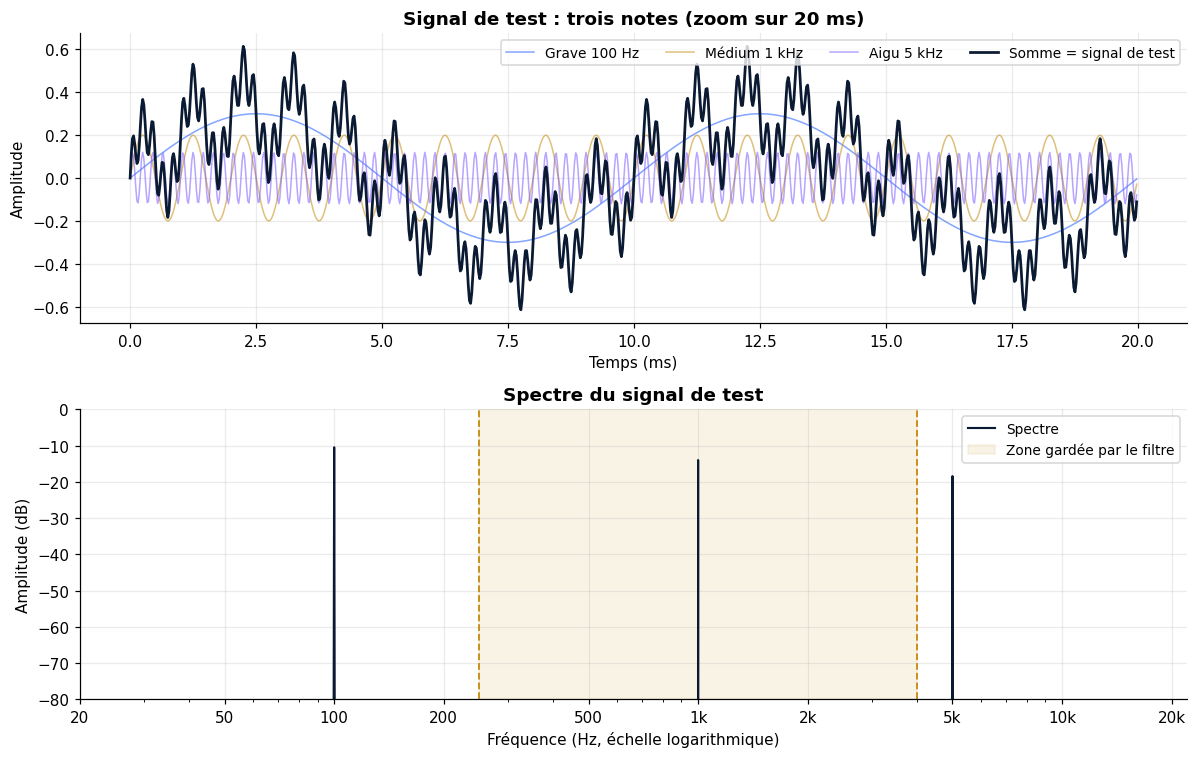

Signal de test — crête : 0.61 (-4.2 dBFS)


In [3]:
tracer_signal()
ecouter(x, "Signal de test")

> **Comment lire le résultat :** en bas, la zone colorée va de 250 Hz à 4 kHz : c'est la bande des médiums. Seul le pic de 1 kHz s'y trouve.

## 2. Passe-bande n° 1 : différence de deux passe-bas

$$\text{médiums} = \text{passe-bas}_{f_2}(x) - \text{passe-bas}_{f_1}(x)$$

- $\text{passe-bas}_{f_2}$ garde **graves + médiums** (tout ce qui est sous 4 kHz).
- $\text{passe-bas}_{f_1}$ garde **les graves seules** (sous 250 Hz).
- Leur différence laisse **les médiums**.

Gain : $H(f) = H_{\text{bas},f_2}(f) - H_{\text{bas},f_1}(f)$

> **Ce que fait la cellule suivante :** elle définit le passe-bande par différence et sa formule de gain, filtre le signal, puis affiche le gain théorique aux deux coupures et au centre de la bande (1 kHz).

In [4]:
def passe_bande_difference(x, f1, f2):
    sous_f2 = passe_bas(x, f2)        # graves + médiums (tout ce qui est sous f2)
    sous_f1 = passe_bas(x, f1)        # graves seules (tout ce qui est sous f1)
    return sous_f2 - sous_f1          # il reste les médiums


def gain_pb_difference(f):
    # Gain = gain du passe-bas à f2 − gain du passe-bas à f1 (en nombres complexes)
    return gain_lissage(f, alpha_pour(F2)) - gain_lissage(f, alpha_pour(F1))


y_diff = passe_bande_difference(x, F1, F2)
for f in (F1, 1000, F2):
    print(f"Gain théorique à {f:>6.0f} Hz : {en_db(gain_pb_difference(f)):+.1f} dB")

Gain théorique à    250 Hz : -3.6 dB
Gain théorique à   1000 Hz : -1.1 dB
Gain théorique à   4000 Hz : -3.5 dB


> **Comment lire le résultat :** environ −3,5 dB aux deux coupures et −1 dB au centre : le passe-bande laisse bien passer le milieu de la bande et commence à couper sur ses bords.

## 3. Passe-bande n° 2 : cascade passe-bas puis passe-haut

On enchaîne deux filtres : le passe-bas à 4 kHz retire les aigus, puis le passe-haut à 250 Hz retire les graves de ce qui reste.

$$\text{médiums} = \text{passe-haut}_{f_1}\big(\text{passe-bas}_{f_2}(x)\big)$$

Quand on enchaîne des filtres, **leurs gains se multiplient** (en dB, ils s'additionnent) :

$$H(f) = H_{\text{bas},f_2}(f) \times H_{\text{haut},f_1}(f)$$

L'ordre ne compte pas : passe-haut puis passe-bas donnerait le même résultat.

> **Ce que fait la cellule suivante :** elle définit le passe-bande en cascade et sa formule de gain, filtre le signal, vérifie que l'ordre des deux filtres ne change rien, puis affiche les gains théoriques.

In [5]:
def passe_bande_cascade(x, f1, f2):
    sans_aigus = passe_bas(x, f2)          # 1er filtre : on retire les aigus
    return passe_haut(sans_aigus, f1)      # 2e filtre : on retire les graves de ce qui reste


def gain_pb_cascade(f):
    # Filtres enchaînés : les gains se multiplient
    return gain_lissage(f, alpha_pour(F2)) * (1 - gain_lissage(f, alpha_pour(F1)))


y_casc = passe_bande_cascade(x, F1, F2)
print("Ordre inversé (passe-haut puis passe-bas) identique :", np.allclose(y_casc, passe_bas(passe_haut(x, F1), F2)))
for f in (F1, 1000, F2):
    print(f"Gain théorique à {f:>6.0f} Hz : {en_db(gain_pb_cascade(f)):+.1f} dB")

Ordre inversé (passe-haut puis passe-bas) identique : True
Gain théorique à    250 Hz : -3.2 dB
Gain théorique à   1000 Hz : -0.7 dB
Gain théorique à   4000 Hz : -3.1 dB


> **Comment lire le résultat :** des valeurs très proches de la méthode n° 1, légèrement moins atténuées. `True` confirme que l'ordre des deux filtres ne compte pas.

## 4. Comparer avant / après

### 4.1 Dans le temps (zoom sur 5 ms)

> **Ce que fait la cellule suivante :** elle superpose, sur 5 ms : le signal d'origine (gris), la **médium seule** (pointillés, la cible idéale) et les sorties des deux passe-bande.

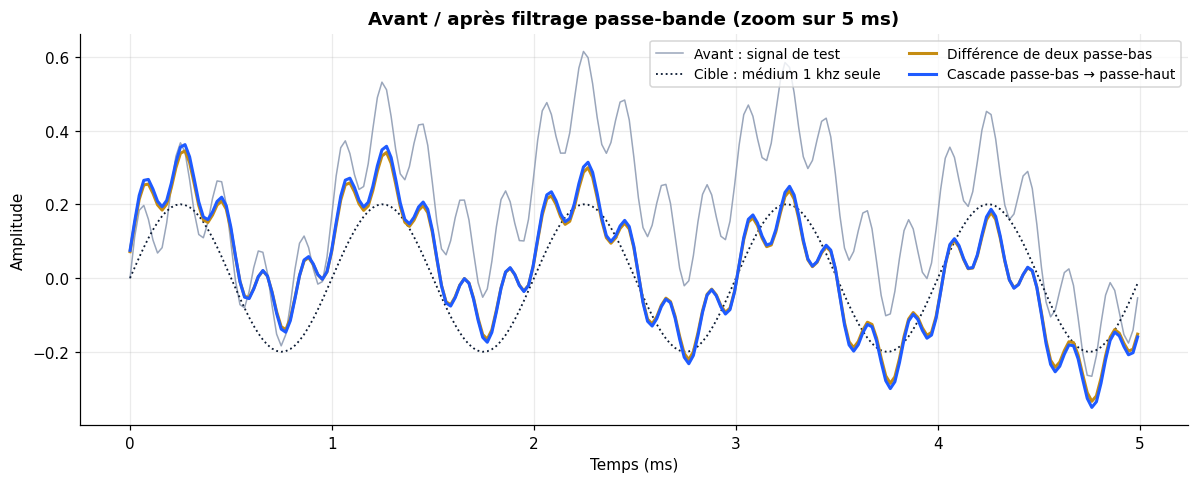

In [6]:
tracer_avant_apres(
    "Médium 1 kHz",
    [(y_diff, OR, "Différence de deux passe-bas"), (y_casc, BLEU, "Cascade passe-bas → passe-haut")],
    duree_ms=5,
    titre="Avant / après filtrage passe-bande (zoom sur 5 ms)",
)

> **Comment lire le résultat :** les deux sorties suivent la médium (5 oscillations en 5 ms), mais ondulent encore un peu : il reste une partie de la grave et de l'aiguë, car les pentes sont douces.

### 4.2 Dans les fréquences

> **Ce que fait la cellule suivante :** elle trace, à gauche, les spectres avant et après chaque passe-bande. À droite, elle résume l'amplitude de chaque note sous forme de barres.

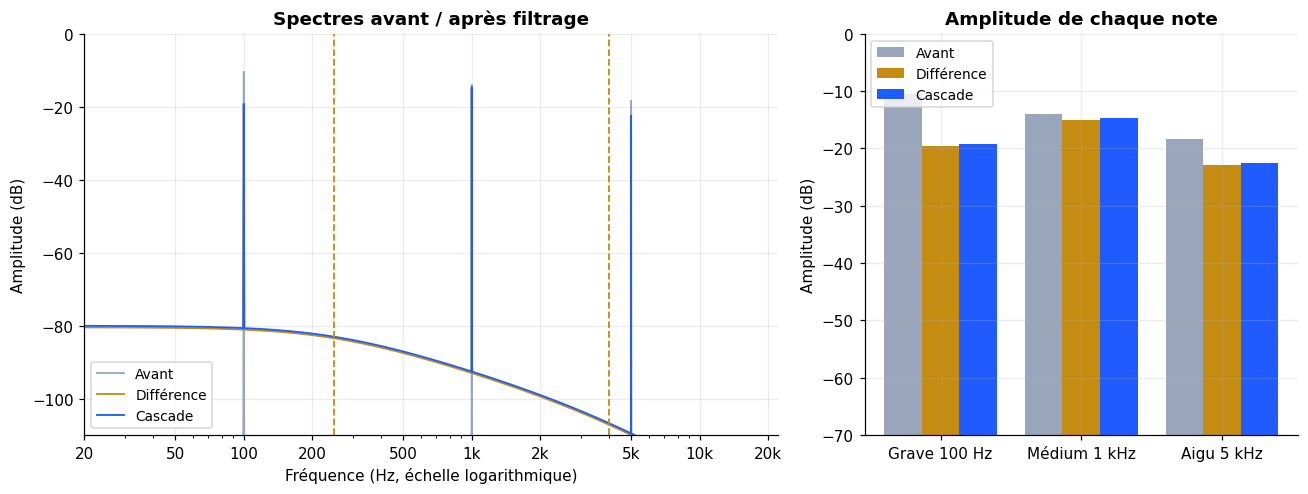

In [7]:
tracer_spectres([(y_diff, OR, "Différence"), (y_casc, BLEU, "Cascade")])

> **Comment lire le résultat :** le pic de 1 kHz reste presque au même niveau. Ceux de 100 Hz et 5 kHz baissent, mais beaucoup moins qu'avec un passe-bas ou un passe-haut seul.

### 4.3 Mesures contre théorie

> **Ce que fait la cellule suivante :** elle compare, pour chaque note, le gain **mesuré** dans le spectre et le gain **prévu** par la formule de chaque méthode.

In [8]:
tableau_mesures([("Différence", y_diff, gain_pb_difference), ("Cascade", y_casc, gain_pb_cascade)])

,Différence : mesuré (dB),Différence : théorie (dB),Cascade : mesuré (dB),Cascade : théorie (dB)
Note,,,,
Grave 100 Hz,-9.2,-9.2,-8.8,-8.8
Médium 1 kHz,-1.1,-1.1,-0.7,-0.7
Aigu 5 kHz,-4.5,-4.5,-4.1,-4.1


> **Comment lire le résultat :** mesure et théorie sont identiques. La médium perd environ 1 dB, la grave environ 9 dB et l'aiguë environ 4 dB.

> **Ce que fait la cellule suivante :** elle trace le gain des deux passe-bande **pour toutes les fréquences** (courbes), avec les mesures (points) et le filtre idéal (gris : un rectangle de 250 Hz à 4 kHz).

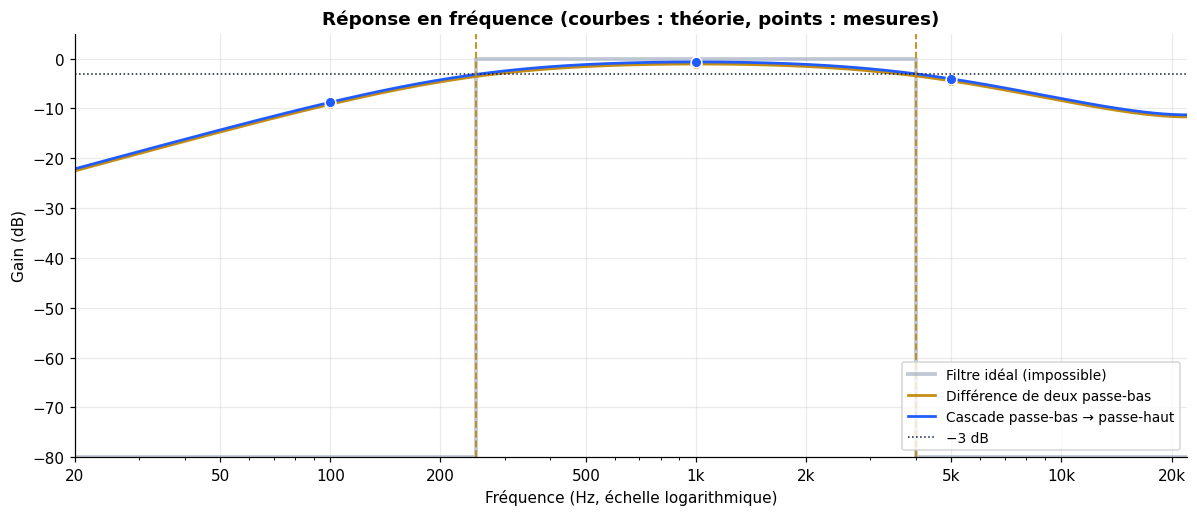

In [9]:
tracer_reponses(
    [(y_diff, gain_pb_difference, OR, "Différence de deux passe-bas"),
     (y_casc, gain_pb_cascade, BLEU, "Cascade passe-bas → passe-haut")],
    ideal=([20, F1, F1, F2, F2, FS / 2], [-80, -80, 0, 0, -80, -80]),
)

**À retenir**

- La courbe a la forme d'une **cloche** : maximale au milieu de la bande, elle descend des deux côtés.
- **Les deux méthodes donnent presque la même courbe.** La cascade atténue un tout petit peu plus, car ses deux gains se multiplient.
- **La médium (1 kHz) passe**, avec environ −1 dB. La grave et l'aiguë sont atténuées, mais seulement de quelques dB à une dizaine de dB.
- La bande des médiums est **très large** (250 Hz → 4 kHz, soit 4 octaves) et les pentes sont douces (ordre 1) : le passe-bande « déborde » nettement sur ses voisines.

### 4.4 À l'écoute

> **Ce que fait la cellule suivante :** elle affiche trois lecteurs : l'original, puis la sortie de chaque passe-bande. La note médium domine, mais on entend encore un peu la grave et l'aiguë.

In [10]:
ecouter(x, "Avant")
ecouter(y_diff, "Différence de deux passe-bas")
ecouter(y_casc, "Cascade passe-bas → passe-haut")

Avant — crête : 0.61 (-4.2 dBFS)


Différence de deux passe-bas — crête : 0.35 (-9.2 dBFS)


Cascade passe-bas → passe-haut — crête : 0.37 (-8.7 dBFS)


## 5. Appliquer un gain à la bande des médiums

1. `mediums = passe_bande(x)` (méthode n° 1, celle d'EGALIZE)
2. `reste = x − mediums` : les graves et les aigus.
3. `x_eq = reste + facteur × mediums`

> **Ce que fait la cellule suivante :** elle applique ces trois étapes avec un gain de **+6 dB**, vérifie qu'à 0 dB on retrouve x et que la crête reste sous 1. Elle trace la séparation, le signal avant / après et les spectres, puis affiche le tableau gain voulu / gain obtenu et les lecteurs.

Changez `G_DB` pour essayer d'autres gains.

Gain des médiums : +6.0 dB (amplitude × 1.995)
Vérification à 0 dB : True
Crête avant : 0.615 — après : 0.906


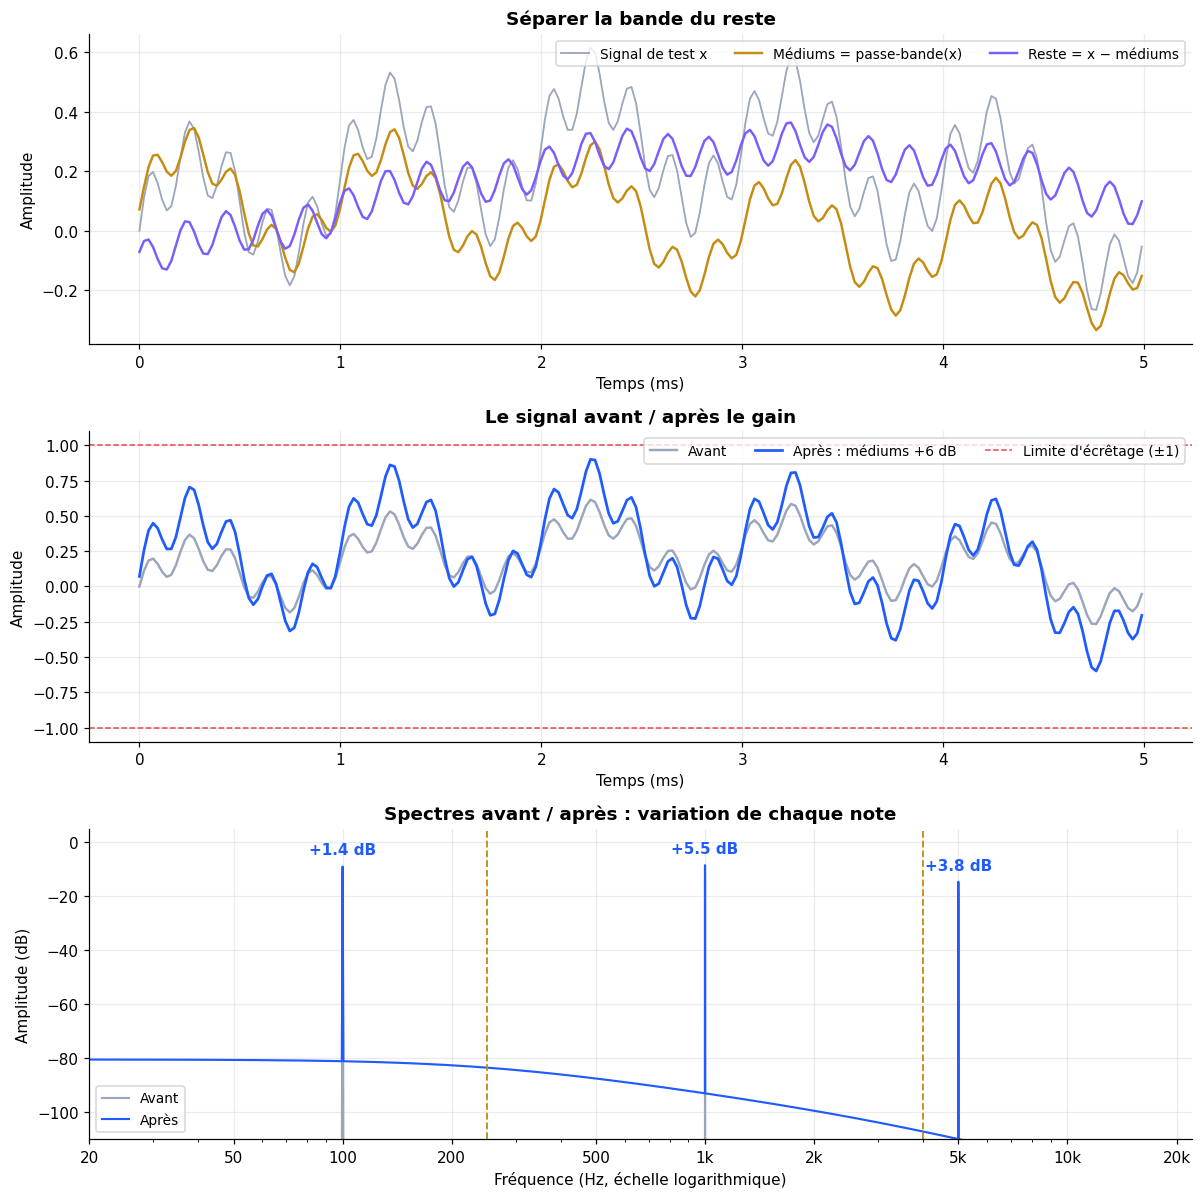

,Gain voulu (dB),Gain obtenu (dB)
Note,,
Grave 100 Hz,+0.0,+1.4
Médium 1 kHz,+6.0,+5.5
Aigu 5 kHz,+0.0,+3.8


Avant — crête : 0.61 (-4.2 dBFS)


Après : médiums +6 dB — crête : 0.91 (-0.9 dBFS)


In [11]:
G_DB = 6.0                                    # gain sur les médiums (dB)
facteur = db_vers_facteur(G_DB)

mediums = passe_bande_difference(x, F1, F2)
reste = x - mediums
x_eq = reste + facteur * mediums

print(f"Gain des médiums : {G_DB:+.1f} dB (amplitude × {facteur:.3f})")
print("Vérification à 0 dB :", np.allclose(reste + mediums, x))
print(f"Crête avant : {np.max(np.abs(x)):.3f} — après : {np.max(np.abs(x_eq)):.3f}")

tracer_gain(x_eq, [(mediums, OR, "Médiums = passe-bande(x)"), (reste, VIOLET, "Reste = x − médiums")],
            f"médiums {G_DB:+.0f} dB", duree_ms=5)
resume_gains(x_eq, {"Grave 100 Hz": 0.0, "Médium 1 kHz": G_DB, "Aigu 5 kHz": 0.0})
ecouter(x, "Avant")
ecouter(x_eq, f"Après : médiums {G_DB:+.0f} dB")

> **Comment lire le résultat :** la médium gagne **+5,5 dB**, presque les +6 demandés. Mais la grave (+1,4 dB) et surtout l'aiguë (+3,8 dB) montent aussi. La bande des médiums est large et ses pentes sont douces, donc elle « déborde » sur ses voisines, qui reçoivent une partie du gain.

## 6. L'égaliseur trois bandes complet

On assemble les trois études :

| Bande | Calcul | Notebook |
|---|---|---|
| Graves | $\text{passe-bas}_{f_1}(x)$ | 01 |
| Médiums | $\text{passe-bas}_{f_2}(x) - \text{passe-bas}_{f_1}(x)$ | 03 |
| Aigus | $x - \text{passe-bas}_{f_2}(x)$ | 02 |

En additionnant les trois lignes, tout se simplifie : **graves + médiums + aigus = x**. Avec tous les gains à 0 dB, l'égaliseur rend exactement le signal d'origine.

C'est exactement le calcul d'EGALIZE (`egaliseur/filtres.py`). L'application fait en plus le filtrage **aller-retour**, pour supprimer le retard vu dans le notebook 01.

> **Ce que fait la cellule suivante :** elle calcule les trois bandes avec seulement **deux passe-bas** (à 250 Hz et à 4 kHz) et vérifie que leur somme redonne x. Elle applique ensuite un gain différent à chaque bande (`GAINS_DB`), additionne, et affiche graphiques, tableau et lecteurs.

graves + médiums + aigus = x ? True
Crête avant : 0.615 — après : 0.677


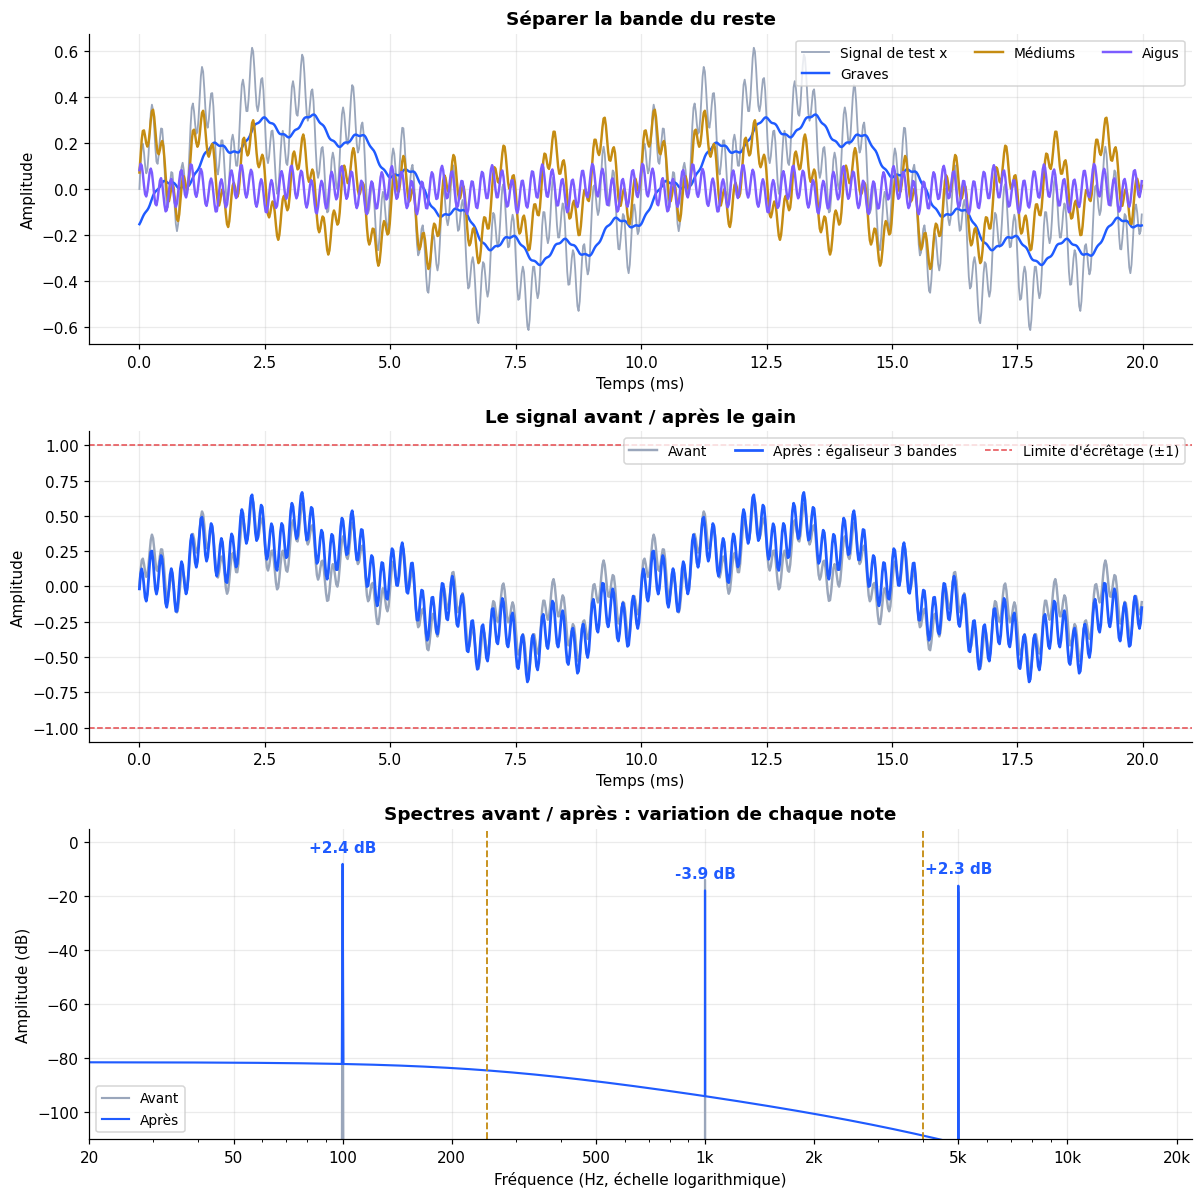

,Gain voulu (dB),Gain obtenu (dB)
Note,,
Grave 100 Hz,+3.0,+2.4
Médium 1 kHz,-6.0,-3.9
Aigu 5 kHz,+6.0,+2.3


Avant — crête : 0.61 (-4.2 dBFS)


Après égalisation 3 bandes — crête : 0.68 (-3.4 dBFS)


In [12]:
GAINS_DB = {"graves": 3.0, "mediums": -6.0, "aigus": 6.0}    # essayez d'autres réglages

pb1, pb2 = passe_bas(x, F1), passe_bas(x, F2)     # les deux seuls filtres nécessaires
bandes = {
    "graves": pb1,           # sous 250 Hz
    "mediums": pb2 - pb1,    # entre 250 Hz et 4 kHz
    "aigus": x - pb2,        # au-dessus de 4 kHz
}

print("graves + médiums + aigus = x ?", np.allclose(sum(bandes.values()), x))

# Égalisation : chaque bande multipliée par son facteur, puis on additionne les trois
x_eq3 = sum(db_vers_facteur(GAINS_DB[nom]) * bande for nom, bande in bandes.items())
print(f"Crête avant : {np.max(np.abs(x)):.3f} — après : {np.max(np.abs(x_eq3)):.3f}")

tracer_gain(x_eq3, [(bandes["graves"], BLEU, "Graves"), (bandes["mediums"], OR, "Médiums"), (bandes["aigus"], VIOLET, "Aigus")],
            "égaliseur 3 bandes", duree_ms=20)
resume_gains(x_eq3, {"Grave 100 Hz": GAINS_DB["graves"], "Médium 1 kHz": GAINS_DB["mediums"], "Aigu 5 kHz": GAINS_DB["aigus"]})
ecouter(x, "Avant")
ecouter(x_eq3, "Après égalisation 3 bandes")

> **Comment lire le résultat :** chaque note bouge dans le bon sens, mais **pas exactement de la valeur demandée** (+2,4 / −3,9 / +2,3 dB au lieu de +3 / −6 / +6). Les bandes se chevauchent (filtres d'ordre 1) : chaque note reçoit un mélange des gains de sa bande et de ses voisines. C'est la principale limite de cette approche, et la raison d'étudier ensuite des filtres plus raides (Butterworth).

## 7. Bilan

| | Différence de deux passe-bas | Cascade |
|---|---|---|
| Formule | $\text{PB}_{f_2}(x) - \text{PB}_{f_1}(x)$ | $\text{PH}_{f_1}(\text{PB}_{f_2}(x))$ |
| Gain | $H_{f_2} - H_{f_1}$ | $H_{f_2} \times (1 - H_{f_1})$ |
| Reconstruction exacte avec les autres bandes | oui | non |
| Utilisé par EGALIZE | oui | — |

La méthode par différence est retenue parce qu'elle garantit **graves + médiums + aigus = x** : à 0 dB, l'égaliseur ne modifie rien.

## 8. À vous de jouer

1. Rétrécissez la bande : `F1 = 800`, `F2 = 1250`. La médium passe-t-elle toujours ? Que deviennent les voisines ?
2. Mettez `GAINS_DB = {"graves": 0, "mediums": 0, "aigus": 0}` : le signal est-il bien inchangé ?
3. Mettez tous les gains à +12 dB : que se passe-t-il pour la crête ?